In [1]:
import numpy as np

**See also: [mp_evaluations.ipynb](mp_evaluations.ipynb)** — Same DMDS Hamiltonian with **constraints** and **filemaker** workflow (evaluator + initial program). The constraint is the **spacetime cost** of the GPU emulator (peak memory from CostAnalyzer, counting per-term precisions). Use `MemoryCost` and the unified dynamics API there.

In [4]:
from trovolut.backends.gpu_mp_emulator.dynamics import (
    Precision, PrecisionConfig, ExpTerm, TrotterSimulator,
    MPTrotterEvolution,
    MPQDriftEvolution,
    MPTaylorEvolution,
    MPPadeEvolution,
    ProductFormula, LieTrotter, SuzukiTrotter, SuzukiHighOrder, suzuki,
)
from trovolut.backends.gpu_mp_emulator.measure import (
    CostAnalyzer, Metrics, CostProfile, print_cost_report
)
from trovolut.backends.gpu_mp_emulator.constraints import (
    MemoryCost, FlopsCost, SpaceTimeCost,
)
from trovolut import qm
from rdkit import Chem
from rdkit.Chem import AllChem
import warnings
warnings.filterwarnings("ignore")

# Generate DMDS molecule
mol = Chem.AddHs(Chem.MolFromSmiles("CSSC"))
AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())
AllChem.UFFOptimizeMolecule(mol)

# Extract XYZ coordinates
conf = mol.GetConformer()
atoms = [a.GetSymbol() for a in mol.GetAtoms()]
xyz = (
    f"{len(atoms)}\ndmds generated by RDKit\n"
    + "\n".join(
        f"{s} {conf.GetAtomPosition(i).x:.8f} "
        f"{conf.GetAtomPosition(i).y:.8f} "
        f"{conf.GetAtomPosition(i).z:.8f}"
        for i, s in enumerate(atoms)
    )
)

# Build the electronic Hamiltonian with minimal active space (4 qubits)
H_fermion = qm.ElectronicHamiltonian.from_xyz(
    xyz_source=xyz,
    basis="sto-3g",
    charge=0,
    spin_mult=1,
    use_gpu4pyscf=False,
    freeze_core=True,
    n_core_keep=1,  # Just HOMO
    n_virt_keep=1,  # Just LUMO -> 2 spatial orbs = 4 qubits (dim 16)
)

# Convert to qubit Hamiltonian via Jordan-Wigner
H_qubit = H_fermion.to_qubits(mapping="jordan-wigner", sparse=True)
qmeta = H_qubit.decompose()

# Get info about the Hamiltonian
meta = H_fermion.meta
print(f"Active space: {meta['n_act_spatial']} spatial orbitals, {meta['n_electrons']} electrons")
print(f"Number of qubits: {qmeta['n_qubits']}")
print(f"Hilbert space dimension: {2**qmeta['n_qubits']}")
print(f"Number of Pauli terms: {len(qmeta['terms'])}")
print(f"\nFirst 10 terms:")
for term in qmeta['terms'][:10]:
    print(term)


converged SCF energy = -864.654938666712
Active space: 2 spatial orbitals, 2 electrons
Number of qubits: 8
Hilbert space dimension: 256
Number of Pauli terms: 31

First 10 terms:
{'coeff': np.float64(-864.7745324137145), 'pauli': 'I'}
{'coeff': np.float64(0.2992851561154677), 'pauli': 'Z0'}
{'coeff': np.float64(-0.00010200001091725735), 'pauli': 'Y0Z1Y2'}
{'coeff': np.float64(-0.00010200001091725735), 'pauli': 'X0Z1X2'}
{'coeff': np.float64(0.2992851561154677), 'pauli': 'Z1'}
{'coeff': np.float64(-0.00010200001091725729), 'pauli': 'Y1Z2Y3'}
{'coeff': np.float64(-0.00010200001091725729), 'pauli': 'X1Z2X3'}
{'coeff': np.float64(0.177364973729019), 'pauli': 'Z2'}
{'coeff': np.float64(0.17736497372901894), 'pauli': 'Z3'}
{'coeff': np.float64(0.0923148318288854), 'pauli': 'Z0Z1'}


In [9]:
def create_terms_with_random_precisions(hamiltonian_terms: list, seed: int = 42) -> list:
    """
    Create ExpTerm objects from Hamiltonian terms with randomly assigned precisions.
    
    Args:
        hamiltonian_terms: List of dictionaries with 'coef' and 'matrix' keys from H.terms()
        seed: Random seed for reproducibility
    
    Returns:
        List of ExpTerm objects
    """
    np.random.seed(seed)
    
    # Available precisions
    precisions = [Precision.FP16, Precision.FP32, Precision.FP64, Precision.BF16, Precision.FP8_E4M3, Precision.FP8_E5M2, Precision.INT8]
    
    # Available decompositions
    decompositions = ["exact", "taylor", "krylov"]
    
    terms = []
    for i, term_data in enumerate(hamiltonian_terms):
        # Get the generator matrix (already includes coefficient)
        matrix = term_data['matrix']
        
        # Convert sparse matrix to dense if needed
        if hasattr(matrix, 'toarray'):
            matrix = matrix.toarray()
        
        generator = term_data['coef'] * matrix
        
        # Randomly assign precision
        precision = np.random.choice(precisions)
        
        # Randomly assign decomposition method
        # decomp = np.random.choice(decompositions)
        decomp = "exact"
        
        # Create ExpTerm
        term_kwargs = {
            "name": f"term_{i}",
            "generator": generator,
            "decomposition": decomp,
            "precision": PrecisionConfig(compute=precision),
        }
        
        # Add taylor_order if using taylor decomposition
        if decomp == "taylor":
            term_kwargs["taylor_order"] = np.random.randint(5, 20)
        
        terms.append(ExpTerm(**term_kwargs))
    
    return terms

# Get Hamiltonian terms (excludes identity term as e^{c*I} is just a global phase)
hamcoeffs = H_qubit.terms()

# Create terms with random precisions
terms = create_terms_with_random_precisions(hamcoeffs)

print(f"Created {len(terms)} ExpTerm objects with random precisions")
print(f"Number of qubits: {qmeta['n_qubits']}")
print(f"State dimension: 2^{qmeta['n_qubits']} = {2**qmeta['n_qubits']}")
print(f"\nFirst 5 terms:")
for i, term in enumerate(terms[:5]):
    print(f"  {term.name}: {term.decomposition}, precision={term.precision.compute}")

print(f"\nTotal number of terms:", len(terms))

Created 31 ExpTerm objects with random precisions
Number of qubits: 8
State dimension: 2^8 = 256

First 5 terms:
  term_0: exact, precision=Precision.INT8
  term_1: exact, precision=Precision.BF16
  term_2: exact, precision=Precision.FP8_E4M3
  term_3: exact, precision=Precision.INT8
  term_4: exact, precision=Precision.FP64

Total number of terms: 31


In [11]:
# Create simulator with H2 Hamiltonian terms
sim = TrotterSimulator(
    terms=terms,
    formula=SuzukiTrotter(),
    n_steps=100,
)

sim.print_precision_summary()


# State dimension based on number of qubits
n = 2**qmeta['n_qubits']


# Run simulation
initial_state = np.random.randn(n) + 1j * np.random.randn(n)
initial_state /= np.linalg.norm(initial_state)

final_state, stats = sim.evolve(initial_state, total_time=1.0, track_stats=True)

print(f"\nPrecision transitions: {stats.precision_transitions}")
print(f"Terms by compute precision: {stats.terms_by_precision}")


MIXED PRECISION TROTTERIZATION SUMMARY

term_0:
  Compute:    int8         (8 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_1:
  Compute:    bfloat16     (16 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_2:
  Compute:    float8_e4m3  (8 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_3:
  Compute:    int8         (8 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_4:
  Compute:    float64      (64 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_5:
  Compute:    float8_e4m3  (8 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Method:     exact

term_6:
  Compute:    float8_e4m3  (8 bits)
  Storage:    float32      (32 bits)
  Accumulate: float64      (64 bits)
  Meth

In [12]:
# Analyze costs
analyzer = CostAnalyzer()
cost = analyzer.analyze(sim, state_dim=n)

# Print detailed report
print_cost_report(cost)

# Compare different formulas using core ProductFormula classes
# LieTrotter (order 1), SuzukiTrotter (order 2), SuzukiHighOrder (order 4)
formula_comparison = analyzer.compare_formulas(
    sim, 
    [LieTrotter(), SuzukiTrotter(), SuzukiHighOrder(4)],
    state_dim=n
)
print_comparison_table(formula_comparison)

# Compare different step counts
step_comparison = analyzer.compare_n_steps(sim, [10, 50, 100, 500], state_dim=n)
print_comparison_table(step_comparison, metric="n_steps scaling")

# Metrics for MPTrotterEvolution
mp_dyn = MPTrotterEvolution(
    trotter_steps=100,
    precision_schedule=Precision.FP32,
)

def mp_test_generator():
    n = 2**qmeta['n_qubits']
    psi0 = np.random.randn(n) + 1j * np.random.randn(n)
    psi0 /= np.linalg.norm(psi0)
    return H_qubit, psi0, 1.0

mp_metrics = Metrics(test_generator=mp_test_generator)
mp_result = mp_metrics(mp_dyn)
print("Mixed-precision metrics:", mp_result)


 SPACETIME COST ANALYSIS

┌─ OVERVIEW ──────────────────────────────────────────────────────────┐
│  Terms: 31          Steps: 100         Sequence/step: 61         │
└─────────────────────────────────────────────────────────────────────┘

┌─ SPACE (MEMORY) ────────────────────────────────────────────────────┐
│  Generator storage:           10.62 MB          │
│  State vector:                 4.00 KB          │
│  Auxiliary (working):          6.00 MB          │
│  ─────────────────────────────────────────────────────────────── │
│  PEAK MEMORY:                 16.63 MB          │
└─────────────────────────────────────────────────────────────────────┘

  Memory by precision:
    bfloat16     │█████                                   │ 1.50 MB
    float16      │                                        │ 256.00 KB
    float32      │███████                                 │ 2.00 MB
    float64      │██████████████████                      │ 5.00 MB
    float8_e4m3  │███                   

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from dataclasses import dataclass
from typing import Callable
import time

# ============================================================
# 1. Error/Accuracy Metrics
# ============================================================

def fidelity(psi1: np.ndarray, psi2: np.ndarray) -> float:
    """Quantum state fidelity |<ψ1|ψ2>|²"""
    return np.abs(np.vdot(psi1, psi2))**2

def infidelity(psi1: np.ndarray, psi2: np.ndarray) -> float:
    """1 - Fidelity (error measure)"""
    return 1 - fidelity(psi1, psi2)

def trace_distance(psi1: np.ndarray, psi2: np.ndarray) -> float:
    """Trace distance between pure states: (1/2)||ρ1 - ρ2||_1"""
    return 0.5 * np.linalg.norm(psi1 - psi2)

def operator_error(U_approx: np.ndarray, U_exact: np.ndarray) -> float:
    """Operator norm error ||U_approx - U_exact||"""
    return np.linalg.norm(U_approx - U_exact, ord=2)


# ============================================================
# 2. Exact Evolution (Ground Truth)
# ============================================================

def exact_evolution(terms: list, total_time: float, state: np.ndarray) -> np.ndarray:
    """
    Compute exact evolution exp(-i H t)|ψ⟩ where H = Σ terms.
    
    IMPORTANT: This uses the ORIGINAL FULL-PRECISION (FP64) Hamiltonian,
    NOT the quantized/mixed-precision versions used by Trotter.
    
    term.get_generator(0) returns the original matrix stored in ExpTerm,
    which is NOT quantized (quantization only happens in Exponentiator._prepare_generator).
    """
    # Ensure state is FP64 complex
    state = state.astype(np.complex128)
    
    # Build full Hamiltonian in FP64
    n = len(state)
    H_total = np.zeros((n, n), dtype=np.complex128)
    
    for term in terms:
        # Get original generator (NOT quantized) and ensure FP64
        H = term.get_generator(0) * term.coefficient
        H = H.astype(np.complex128)  # Explicit FP64 cast
        H_total += H
    
    # Exact matrix exponential (scipy uses FP64 for complex128)
    U_exact = expm(-1j * H_total * total_time)
    return U_exact @ state


# ============================================================
# 3. Tradeoff Analysis Class
# ============================================================

@dataclass
class TradeoffPoint:
    """Single point in the accuracy-cost tradeoff."""
    formula_name: str
    n_steps: int
    
    # Accuracy metrics
    infidelity: float
    trace_distance: float
    
    # Cost metrics
    total_depth: int
    total_flops: int
    wall_time_seconds: float
    
    # Derived
    @property
    def error(self) -> float:
        return self.infidelity


class AccuracyCostAnalyzer:
    """Analyzes accuracy vs computational cost tradeoffs."""
    
    def __init__(self, terms: list, state_dim: int):
        self.terms = terms
        self.n = state_dim
        self.cost_analyzer = CostAnalyzer()
        
    def analyze_tradeoff(
        self,
        formulas: dict[str, ProductFormula],
        step_counts: list[int],
        total_time: float,
        initial_state: np.ndarray | None = None,
        n_random_states: int = 1,
    ) -> list[TradeoffPoint]:
        """
        Analyze accuracy vs cost for different formulas and step counts.
        
        Args:
            formulas: Dict of {name: ProductFormula}
            step_counts: List of n_steps values to try
            total_time: Total evolution time
            initial_state: Initial state (random if None)
            n_random_states: Number of random states to average over
        """
        results = []
        
        # Generate test states
        if initial_state is not None:
            test_states = [initial_state]
        else:
            test_states = [
                self._random_state() for _ in range(n_random_states)
            ]
        
        # Compute exact evolution for each test state
        exact_finals = [
            exact_evolution(self.terms, total_time, psi) 
            for psi in test_states
        ]
        
        # Test each configuration
        total_configs = len(formulas) * len(step_counts)
        config_idx = 0
        
        for formula_name, formula in formulas.items():
            for n_steps in step_counts:
                config_idx += 1
                print(f"\rAnalyzing [{config_idx}/{total_configs}]: "
                      f"{formula_name}, steps={n_steps}    ", end="")
                
                # Create simulator
                sim = TrotterSimulator(
                    terms=self.terms,
                    formula=formula,
                    n_steps=n_steps,
                )
                
                # Get cost metrics
                cost = self.cost_analyzer.analyze(sim, state_dim=self.n)
                
                # Measure accuracy (average over test states)
                infidelities = []
                trace_dists = []
                
                start_time = time.perf_counter()
                
                for psi_init, psi_exact in zip(test_states, exact_finals):
                    psi_start = psi_init.copy()
                    psi_trotter, _ = sim.evolve(psi_start, total_time)
                    
                    infidelities.append(infidelity(psi_trotter, psi_exact))
                    trace_dists.append(trace_distance(psi_trotter, psi_exact))
                
                wall_time = time.perf_counter() - start_time
                
                results.append(TradeoffPoint(
                    formula_name=formula_name,
                    n_steps=n_steps,
                    infidelity=np.mean(infidelities),
                    trace_distance=np.mean(trace_dists),
                    total_depth=cost.total_depth,
                    total_flops=cost.total_flops,
                    wall_time_seconds=wall_time / len(test_states),
                ))
        
        print("\nDone!")
        return results
    
    def _random_state(self) -> np.ndarray:
        """Generate random normalized state."""
        psi = (np.random.randn(self.n) + 1j * np.random.randn(self.n)).astype(np.complex128)
        return psi / np.linalg.norm(psi)


# ============================================================
# 4. Visualization Functions
# ============================================================

def plot_accuracy_vs_cost(
    results: list[TradeoffPoint],
    cost_metric: str = "total_depth",
    error_metric: str = "infidelity",
    title: str = "Accuracy vs Computational Cost",
    figsize: tuple = (12, 5),
):
    """
    Plot accuracy-cost tradeoff curves.
    
    Args:
        results: List of TradeoffPoint objects
        cost_metric: 'total_depth', 'total_flops', or 'wall_time_seconds'
        error_metric: 'infidelity' or 'trace_distance'
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # Group by formula
    formulas = {}
    for r in results:
        if r.formula_name not in formulas:
            formulas[r.formula_name] = []
        formulas[r.formula_name].append(r)
    
    # Color map
    colors = plt.cm.tab10(np.linspace(0, 1, len(formulas)))
    markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p']
    
    # --- Left plot: Linear scale ---
    ax1 = axes[0]
    for idx, (name, points) in enumerate(formulas.items()):
        costs = [getattr(p, cost_metric) for p in points]
        errors = [getattr(p, error_metric) for p in points]
        
        # Sort by cost
        sorted_pairs = sorted(zip(costs, errors))
        costs, errors = zip(*sorted_pairs)
        
        ax1.plot(costs, errors, '-o', 
                 color=colors[idx], 
                 marker=markers[idx % len(markers)],
                 label=name, 
                 markersize=8,
                 linewidth=2)
    
    ax1.set_xlabel(_format_label(cost_metric), fontsize=12)
    ax1.set_ylabel(_format_label(error_metric), fontsize=12)
    ax1.set_title(f'{title} (Linear Scale)', fontsize=14)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # --- Right plot: Log-log scale ---
    ax2 = axes[1]
    for idx, (name, points) in enumerate(formulas.items()):
        costs = [getattr(p, cost_metric) for p in points]
        errors = [getattr(p, error_metric) for p in points]
        
        # Filter out zero errors for log scale
        valid = [(c, e) for c, e in zip(costs, errors) if e > 0]
        if valid:
            costs, errors = zip(*sorted(valid))
            ax2.loglog(costs, errors, '-o',
                      color=colors[idx],
                      marker=markers[idx % len(markers)],
                      label=name,
                      markersize=8,
                      linewidth=2)
    
    ax2.set_xlabel(_format_label(cost_metric), fontsize=12)
    ax2.set_ylabel(_format_label(error_metric), fontsize=12)
    ax2.set_title(f'{title} (Log-Log Scale)', fontsize=14)
    ax2.legend()
    ax2.grid(True, alpha=0.3, which='both')
    
    plt.tight_layout()
    return fig


def plot_scaling_analysis(
    results: list[TradeoffPoint],
    figsize: tuple = (14, 10),
):
    """
    Comprehensive scaling analysis with multiple subplots.
    """
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    
    formulas = {}
    for r in results:
        if r.formula_name not in formulas:
            formulas[r.formula_name] = []
        formulas[r.formula_name].append(r)
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(formulas)))
    
    # --- (0,0): Error vs Steps ---
    ax = axes[0, 0]
    for idx, (name, points) in enumerate(formulas.items()):
        steps = [p.n_steps for p in points]
        errors = [p.infidelity for p in points]
        sorted_pairs = sorted(zip(steps, errors))
        steps, errors = zip(*sorted_pairs)
        ax.loglog(steps, errors, '-o', color=colors[idx], label=name, markersize=6)
    
    ax.set_xlabel('Number of Trotter Steps', fontsize=11)
    ax.set_ylabel('Infidelity', fontsize=11)
    ax.set_title('Error vs Steps (expect power law)', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3, which='both')
    
    # --- (0,1): Error vs Depth ---
    ax = axes[0, 1]
    for idx, (name, points) in enumerate(formulas.items()):
        depth = [p.total_depth for p in points]
        errors = [p.infidelity for p in points]
        valid = [(d, e) for d, e in zip(depth, errors) if e > 0]
        if valid:
            depth, errors = zip(*sorted(valid))
            ax.loglog(depth, errors, '-o', color=colors[idx], label=name, markersize=6)
    
    ax.set_xlabel('Total Depth', fontsize=11)
    ax.set_ylabel('Infidelity', fontsize=11)
    ax.set_title('Error vs Depth (true cost comparison)', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3, which='both')
    
    # --- (1,0): Cost efficiency (error × depth) ---
    ax = axes[1, 0]
    for idx, (name, points) in enumerate(formulas.items()):
        steps = [p.n_steps for p in points]
        efficiency = [p.infidelity * p.total_depth for p in points]
        sorted_pairs = sorted(zip(steps, efficiency))
        steps, efficiency = zip(*sorted_pairs)
        ax.semilogy(steps, efficiency, '-o', color=colors[idx], label=name, markersize=6)
    
    ax.set_xlabel('Number of Trotter Steps', fontsize=11)
    ax.set_ylabel('Error × Depth (lower is better)', fontsize=11)
    ax.set_title('Cost-Efficiency Metric', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3, which='both')
    
    # --- (1,1): Pareto frontier ---
    ax = axes[1, 1]
    all_points = []
    for idx, (name, points) in enumerate(formulas.items()):
        for p in points:
            if p.infidelity > 0:
                ax.scatter(p.total_depth, p.infidelity, 
                          color=colors[idx], s=50, alpha=0.6)
                all_points.append((p.total_depth, p.infidelity, name))
    
    # Find and highlight Pareto frontier
    pareto = _find_pareto_frontier(all_points)
    pareto_depths, pareto_errors, _ = zip(*pareto)
    ax.plot(pareto_depths, pareto_errors, 'k--', linewidth=2, label='Pareto Frontier')
    ax.scatter(pareto_depths, pareto_errors, c='red', s=100, zorder=5, 
               edgecolors='black', linewidths=2)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total Depth', fontsize=11)
    ax.set_ylabel('Infidelity', fontsize=11)
    ax.set_title('Pareto Frontier (optimal tradeoffs)', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3, which='both')
    
    plt.tight_layout()
    return fig


def plot_error_scaling_exponent(
    results: list[TradeoffPoint],
    figsize: tuple = (10, 6),
):
    """
    Fit and display error scaling exponents.
    Expected: Error ~ O(dt^p) where p is the order of the method.
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    formulas = {}
    for r in results:
        if r.formula_name not in formulas:
            formulas[r.formula_name] = []
        formulas[r.formula_name].append(r)
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(formulas)))
    
    print("\n" + "=" * 60)
    print(" ERROR SCALING ANALYSIS")
    print("=" * 60)
    print(f" {'Formula':<20} {'Fitted Exponent':>15} {'Expected':>10}")
    print("-" * 60)
    
    expected_orders = {
        'LieTrotter': 1,
        'SuzukiTrotter': 2,
        'SuzukiHighOrder': 4,
    }
    
    for idx, (name, points) in enumerate(formulas.items()):
        # Sort by steps
        points = sorted(points, key=lambda p: p.n_steps)
        
        steps = np.array([p.n_steps for p in points])
        errors = np.array([p.infidelity for p in points])
        
        # Filter valid points for fitting
        valid = errors > 1e-15
        if np.sum(valid) < 2:
            continue
            
        steps_valid = steps[valid]
        errors_valid = errors[valid]
        
        # dt ~ 1/n_steps, so error ~ (1/n_steps)^p means log(error) ~ -p*log(steps)
        log_steps = np.log(steps_valid)
        log_errors = np.log(errors_valid)
        
        # Linear fit
        coeffs = np.polyfit(log_steps, log_errors, 1)
        fitted_exponent = -coeffs[0]  # negative because error decreases with steps
        
        expected = expected_orders.get(name, '?')
        print(f" {name:<20} {fitted_exponent:>15.2f} {expected:>10}")
        
        # Plot data
        ax.loglog(steps, errors, 'o', color=colors[idx], markersize=8, label=f'{name} (data)')
        
        # Plot fit line
        fit_steps = np.logspace(np.log10(steps.min()), np.log10(steps.max()), 50)
        fit_errors = np.exp(coeffs[1]) * fit_steps**coeffs[0]
        ax.loglog(fit_steps, fit_errors, '--', color=colors[idx], alpha=0.7,
                 label=f'{name} (fit: n^{{{-coeffs[0]:.1f}}})')
    
    print("=" * 60)
    
    ax.set_xlabel('Number of Trotter Steps (n)', fontsize=12)
    ax.set_ylabel('Infidelity', fontsize=12)
    ax.set_title('Error Scaling: Infidelity ~ O(1/n^p)', fontsize=14)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3, which='both')
    
    plt.tight_layout()
    return fig


def _find_pareto_frontier(points: list[tuple]) -> list[tuple]:
    """Find Pareto-optimal points (minimize both cost and error)."""
    sorted_points = sorted(points, key=lambda x: x[0])  # sort by cost
    pareto = []
    min_error = float('inf')
    
    for p in sorted_points:
        if p[1] < min_error:
            pareto.append(p)
            min_error = p[1]
    
    return pareto


def _format_label(metric: str) -> str:
    """Format metric name for axis labels."""
    labels = {
        'total_depth': 'Total Depth (sequential ops)',
        'total_flops': 'Total FLOPs',
        'wall_time_seconds': 'Wall Clock Time (s)',
        'infidelity': 'Infidelity (1 - |⟨ψ_exact|ψ_trotter⟩|²)',
        'trace_distance': 'Trace Distance',
    }
    return labels.get(metric, metric)


def print_tradeoff_table(results: list[TradeoffPoint]):
    """Print results as a formatted table."""
    print("\n" + "=" * 90)
    print(" ACCURACY VS COST TRADEOFF RESULTS")
    print("=" * 90)
    print(f" {'Formula':<20} {'Steps':>7} {'Infidelity':>12} {'Depth':>12} {'FLOPs':>12} {'Time(s)':>10}")
    print("-" * 90)
    
    # Sort by formula then steps
    sorted_results = sorted(results, key=lambda r: (r.formula_name, r.n_steps))
    
    current_formula = None
    for r in sorted_results:
        if r.formula_name != current_formula:
            if current_formula is not None:
                print("-" * 90)
            current_formula = r.formula_name
        
        print(f" {r.formula_name:<20} {r.n_steps:>7} {r.infidelity:>12.2e} "
              f"{r.total_depth:>12,} {r.total_flops:>12,} {r.wall_time_seconds:>10.4f}")
    
    print("=" * 90)


In [14]:
import os
import pickle

# Create data directory
os.makedirs('data', exist_ok=True)

# Define formulas to compare (instances, not classes)
formula_classes = {
    'First Order': LieTrotter,
    'Second Order': SuzukiTrotter,
    'Fourth Order': lambda: SuzukiHighOrder(4),
}

# Step counts to analyze
step_counts = [2, 4, 8, 16, 32, 64]

# State dimension
n = 2**qmeta['n_qubits']

# Precision configurations to test
precision_configs = {
    'FP16': Precision.FP16,
    'FP64': Precision.FP64,
    'Mixed': 'random'
}

# Helper function to create terms with specific precision
def create_terms_with_precision(hamcoeffs, precision_choice, seed=42):
    """
    Create terms with specific precision configuration.
    
    IMPORTANT: The generator stored in ExpTerm is the ORIGINAL FP64 matrix.
    Precision quantization only happens during Trotter evolution via
    Exponentiator._prepare_generator(), NOT in exact_evolution().
    """
    np.random.seed(seed)
    
    decompositions = ["exact", "taylor", "krylov"]
    terms_list = []
    
    for i, term_data in enumerate(hamcoeffs):
        matrix = term_data['matrix']
        if hasattr(matrix, 'toarray'):
            matrix = matrix.toarray()
        
        # Store ORIGINAL FP64 matrix (coefficient already applied)
        # This will be used as-is for exact evolution
        # Trotter will quantize it based on precision config
        generator = (term_data['coef'] * matrix).astype(np.complex128)
        
        # Set precision based on configuration
        if precision_choice == 'random':
            precision = np.random.choice([Precision.FP16, Precision.FP32, Precision.FP64])
        else:
            precision = precision_choice
        
        decomp = np.random.choice(decompositions)
        
        term_kwargs = {
            "name": f"term_{i}",
            "generator": generator,
            "decomposition": decomp,
            "precision": PrecisionConfig(compute=precision),
        }
        
        if decomp == "taylor":
            term_kwargs["taylor_order"] = np.random.randint(5, 20)
        
        terms_list.append(ExpTerm(**term_kwargs))
    
    return terms_list

# Number of random states to test per configuration (no need for multiple trials since simulation is deterministic)
N_RANDOM_STATES = 5

# Run analysis for all combinations
all_results = []

print("Running comprehensive accuracy-cost tradeoff analysis...")
print(f"State dimension: {n}")
print(f"Total time: 1.0")
print(f"Random states per configuration: {N_RANDOM_STATES}")
print(f"Formulas: {list(formula_classes.keys())}")
print(f"Precisions: {list(precision_configs.keys())}")
print(f"Step counts: {step_counts}")
print()

total_configs = len(formula_classes) * len(precision_configs) * len(step_counts)
config_counter = 0

for formula_name, FormulaClass in formula_classes.items():
    for prec_name, prec_value in precision_configs.items():
        print(f"\n{'='*70}")
        print(f"Formula: {formula_name}, Precision: {prec_name}")
        print(f"{'='*70}")
        
        # Run for each step count
        for n_steps in step_counts:
            config_counter += 1
            print(f"\r[{config_counter}/{total_configs}] {formula_name}-{prec_name}, steps={n_steps}    ", end="", flush=True)
            
            # Use unique seed for this configuration
            config_seed = 42 + config_counter * 1000
            
            # Create terms with this precision configuration
            terms_config = create_terms_with_precision(hamcoeffs, prec_value, seed=config_seed)
            
            # Create simulator
            sim = TrotterSimulator(
                terms=terms_config,
                formula=FormulaClass(),
                n_steps=n_steps,
            )
            
            # Get cost metrics (deterministic, only depends on simulator configuration)
            cost_analyzer = CostAnalyzer()
            cost_metrics = cost_analyzer.analyze(sim, state_dim=n)
            
            # Generate N_RANDOM_STATES different random initial states
            np.random.seed(config_seed + 1000)
            test_states = [(np.random.randn(n) + 1j * np.random.randn(n)).astype(np.complex128) 
                          for _ in range(N_RANDOM_STATES)]
            test_states = [psi / np.linalg.norm(psi) for psi in test_states]
            
            # Compute exact evolution for all states
            exact_finals = [exact_evolution(terms_config, 1.0, psi) for psi in test_states]
            
            # Simulate and compute infidelity for each state
            infidelities = []
            for psi_init, psi_exact in zip(test_states, exact_finals):
                psi_start = psi_init.copy().astype(np.complex128)
                psi_trotter, _ = sim.evolve(psi_start, 1.0)
                infidelities.append(infidelity(psi_trotter, psi_exact))
            
            # Store result with statistics across the N_RANDOM_STATES states
            result = {
                'formula': formula_name,
                'precision': prec_name,
                'n_steps': n_steps,
                'infidelity_mean': np.mean(infidelities),
                'infidelity_std': np.std(infidelities),
                'infidelity_all': infidelities,  # Keep individual infidelities
                'total_depth': cost_metrics.total_depth,
                'total_flops': cost_metrics.total_flops,
            }
            all_results.append(result)

print("\n\n" + "="*70)
print(f"Completed! Processed {len(all_results)} configurations")
print(f"Each configuration tested on {N_RANDOM_STATES} random states")
print(f"Total simulations: {len(all_results) * N_RANDOM_STATES}")
print("="*70)

# Save results
with open('data/tradeoff_results.pkl', 'wb') as f:
    pickle.dump(all_results, f)
print(f"Saved results to data/tradeoff_results.pkl")

print(f"Saved {len(all_results)} results to data/tradeoff_results.pkl")


Running comprehensive accuracy-cost tradeoff analysis...
State dimension: 256
Total time: 1.0
Random states per configuration: 5
Formulas: ['First Order', 'Second Order', 'Fourth Order']
Precisions: ['FP16', 'FP64', 'Mixed']
Step counts: [2, 4, 8, 16, 32, 64]


Formula: First Order, Precision: FP16
[6/54] First Order-FP16, steps=64    
Formula: First Order, Precision: FP64
[12/54] First Order-FP64, steps=64    
Formula: First Order, Precision: Mixed
[18/54] First Order-Mixed, steps=64    
Formula: Second Order, Precision: FP16
[24/54] Second Order-FP16, steps=64    
Formula: Second Order, Precision: FP64
[30/54] Second Order-FP64, steps=64    
Formula: Second Order, Precision: Mixed
[36/54] Second Order-Mixed, steps=64    
Formula: Fourth Order, Precision: FP16
[42/54] Fourth Order-FP16, steps=64    
Formula: Fourth Order, Precision: FP64
[48/54] Fourth Order-FP64, steps=64    
Formula: Fourth Order, Precision: Mixed
[54/54] Fourth Order-Mixed, steps=64    

Completed! Processed 54 con

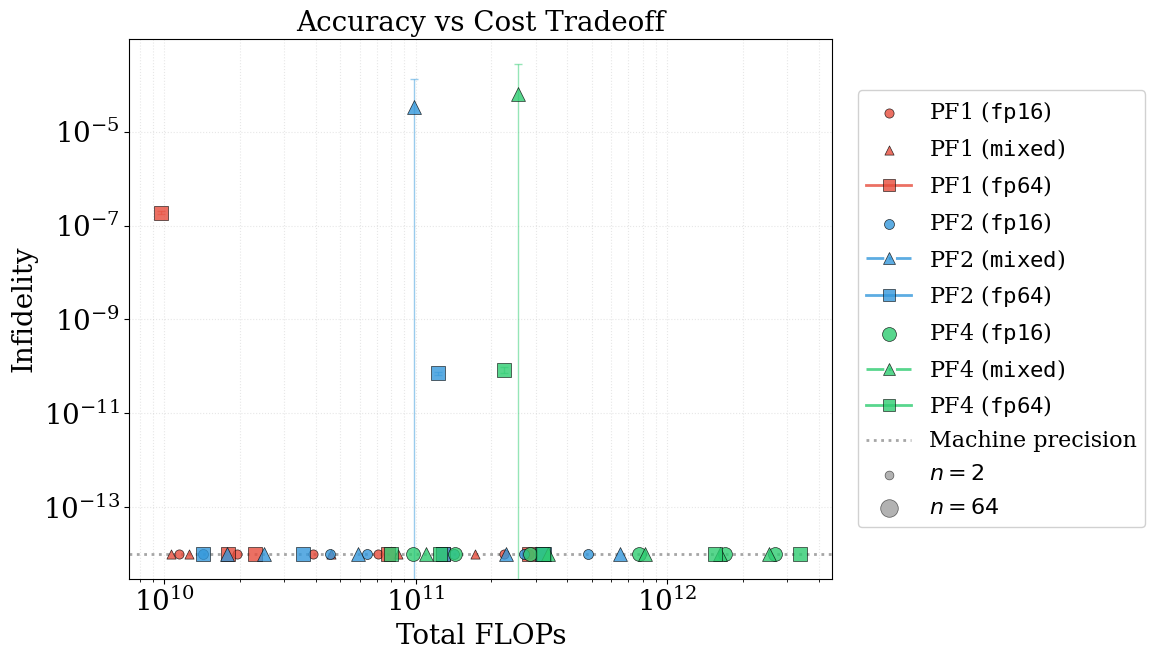

Plot saved to data/infidelity_vs_total_flops.pdf and data/infidelity_vs_total_flops.png
Using cost metric: total_flops, error metric: infidelity
Filtered out points with infidelity < 1e-14


In [94]:
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURATION: Change these to plot different metrics
# ============================================================
# Cost metric options: 'total_depth', 'total_flops'
# COST_METRIC = 'total_depth'
COST_METRIC = 'total_flops'  # Uncomment to use FLOPs instead

# Error metric options: 'infidelity', 'trace_distance' (if available)
ERROR_METRIC = 'infidelity'
# For accessing results with statistics
ERROR_METRIC_MEAN = ERROR_METRIC + '_mean'
ERROR_METRIC_STD = ERROR_METRIC + '_std'

# Minimum error threshold to avoid log scale issues
MIN_ERROR = 1e-14

# Metric display names
METRIC_LABELS = {
    'total_depth': 'Total Depth',
    'total_flops': 'Total FLOPs',
    'infidelity': 'Infidelity',
    'trace_distance': 'Trace Distance',
}
# ============================================================

# Set plot style
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 20
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['legend.fontsize'] = 16

# Load results
with open('data/tradeoff_results.pkl', 'rb') as f:
    all_results = pickle.load(f)

# Create plot
fig, ax = plt.subplots(1, 1, figsize=(12, 7))

# Define colors and markers for each configuration
# Colors = formula order, Markers = precision
formula_colors = {'First Order': '#E74C3C', 'Second Order': '#3498DB', 'Fourth Order': '#2ECC71'}
formula_labels = {'First Order': 'PF1', 'Second Order': 'PF2', 'Fourth Order': 'PF4'}
precision_markers = {'FP16': 'o', 'FP64': 's', 'Mixed': '^'}
precision_linestyles = {'FP16': '--', 'FP64': '-', 'Mixed': '-.'}
precision_labels = {'FP16': 'fp16', 'FP64': 'fp64', 'Mixed': 'mixed'}

# Group results by formula and precision
for formula_name in ['First Order', 'Second Order', 'Fourth Order']:
    for prec_name in ['FP16', 'Mixed', 'FP64']:
        # Filter results for this configuration
        config_results = [r for r in all_results 
                         if r['formula'] == formula_name and r['precision'] == prec_name]
        
        if not config_results:
            continue
        
        # Sort by cost metric
        config_results = sorted(config_results, key=lambda x: x[COST_METRIC])
        
        # Extract data and separate near-zero errors
        costs = []
        errors = []
        error_stds = []
        costs_zero = []  # For machine precision points
        for r in config_results:
            if r[ERROR_METRIC_MEAN] > MIN_ERROR:
                costs.append(r[COST_METRIC])
                errors.append(r[ERROR_METRIC_MEAN])
                error_stds.append(r[ERROR_METRIC_STD])
            else:
                # Store points that achieved machine precision
                costs_zero.append(r[COST_METRIC])
        
        if len(costs) == 0 and len(costs_zero) == 0:
            continue
        
        # Create label with short formula name and monospace precision
        label = f"{formula_labels[formula_name]} ($\\mathtt{{{precision_labels[prec_name]}}}$)"
        
        # Plot regular points with both lines and markers
        if len(costs) > 0:
            costs = np.array(costs)
            errors = np.array(errors)
            error_stds = np.array(error_stds)
            
            # Get n_steps for sizing markers
            n_steps_vals = np.array([r['n_steps'] for r in config_results 
                                     if r[ERROR_METRIC_MEAN] > MIN_ERROR])
            # Normalize marker sizes: scale n_steps to range (40-160)
            if len(n_steps_vals) > 1:
                marker_sizes = 40 + (n_steps_vals - n_steps_vals.min()) / (n_steps_vals.max() - n_steps_vals.min()) * 120
            else:
                marker_sizes = [100]  # Single point gets medium size
            
            # Plot line first (no label, no marker)
            ax.plot(costs, errors, 
                   color=formula_colors[formula_name],
                   linestyle=precision_linestyles[prec_name],
                   linewidth=2,
                   alpha=0.8)
            
            # Add error bars (std dev across trials)
            ax.errorbar(costs, errors, yerr=error_stds,
                       fmt='none',  # No line/marker, just error bars
                       ecolor=formula_colors[formula_name],
                       elinewidth=1,
                       capsize=3,
                       alpha=0.5,
                       zorder=4)
            
            # Add markers with variable size (no label)
            ax.scatter(costs, errors,
                      marker=precision_markers[prec_name],
                      s=marker_sizes,
                      color=formula_colors[formula_name],
                      edgecolors='black',
                      linewidths=0.5,
                      alpha=0.8,
                      zorder=5)
            
            # Add dummy plot for legend (line + marker)
            ax.plot([], [], 
                   marker=precision_markers[prec_name],
                   color=formula_colors[formula_name],
                   linestyle=precision_linestyles[prec_name],
                   linewidth=2,
                   markersize=8,
                   label=label,
                   markeredgecolor='black',
                   markeredgewidth=0.5,
                   alpha=0.8)
        
        # Plot machine precision points at the bottom (no label, same style)
        if len(costs_zero) > 0:
            costs_zero = np.array(costs_zero)
            # Plot at MIN_ERROR to show they achieved machine precision
            errors_zero = np.full_like(costs_zero, MIN_ERROR, dtype=float)
            
            # Get n_steps for these points
            n_steps_zero = np.array([r['n_steps'] for r in config_results 
                                    if r[ERROR_METRIC_MEAN] <= MIN_ERROR])
            if len(n_steps_zero) > 0:
                marker_sizes_zero = 40 + (n_steps_zero - step_counts[0]) / (step_counts[-1] - step_counts[0]) * 120
            else:
                marker_sizes_zero = [100]
            
            ax.scatter(costs_zero, errors_zero, 
                      marker=precision_markers[prec_name],
                      color=formula_colors[formula_name],  # Same filled markers
                      s=marker_sizes_zero,
                      edgecolors='black',
                      linewidths=0.5,
                      label=label if len(costs) == 0 else None,  # Only label if no regular points
                      alpha=0.8,
                      zorder=10)  # Plot on top

# Set log scale
ax.set_xscale('log')
ax.set_yscale('log')

# Add horizontal line at machine precision
ax.axhline(y=MIN_ERROR, color='gray', linestyle=':', linewidth=2, alpha=0.7, 
           label='Machine precision', zorder=1)



# Formatting with dynamic labels
ax.set_xlabel(METRIC_LABELS[COST_METRIC])
ax.set_ylabel(METRIC_LABELS[ERROR_METRIC])
ax.grid(True, which='both', alpha=0.3, linestyle=':')
ax.set_title('Accuracy vs Cost Tradeoff')

# Add size reference markers to legend
for n_step_ref in [step_counts[0], step_counts[-1]]:
    size_ref = 40 + (n_step_ref - step_counts[0]) / (step_counts[-1] - step_counts[0]) * 120
    ax.scatter([], [], s=size_ref, color='gray', edgecolors='black', linewidths=0.5,
              label=f'$n={n_step_ref}$', alpha=0.6)

# Place legend outside the plot area (to the right)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.9, ncol=1)

plt.tight_layout()

# Save with metric-specific filename
output_base = f'data/{ERROR_METRIC}_vs_{COST_METRIC}'
plt.savefig(f'{output_base}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{output_base}.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Plot saved to {output_base}.pdf and {output_base}.png")
print(f"Using cost metric: {COST_METRIC}, error metric: {ERROR_METRIC}")
print(f"Filtered out points with {ERROR_METRIC} < {MIN_ERROR}")

In [ ]:
## Unified Mixed-Precision API

The cells above show the low-level `TrotterSimulator` + `CostAnalyzer` workflow.
Below we use the **unified dynamics + metrics** API:

- **4 dynamics methods**: `MPTrotterEvolution`, `MPQDriftEvolution`,
  `MPTaylorEvolution`, `MPPadeEvolution`
- **1 Metrics class** that works with all of them
- **MemoryCost / FlopsCost / SpaceTimeCost** constraints that score the `CostProfile`

In [ ]:
# ============================================================
# 1. Create a mixed-precision schedule for the Hamiltonian
# ============================================================
# Assign precisions per term: alternate between FP32, FP16, BF16
precisions_cycle = [Precision.FP32, Precision.FP16, Precision.BF16]
precision_schedule = [precisions_cycle[i % len(precisions_cycle)]
                      for i in range(len(hamcoeffs))]

print(f"Hamiltonian has {len(hamcoeffs)} terms")
print("Precision schedule (first 9):", [p.value for p in precision_schedule[:9]])

# State dimension
n = 2**qmeta['n_qubits']

# Build a test generator for Metrics
# (returns (hamiltonian, psi0, t) tuples)
psi0 = np.zeros(n, dtype=np.complex128)
psi0[0] = 1.0  # computational basis |0...0>

def test_generator():
    return (H_qubit, psi0, 1.0)

In [ ]:
# ============================================================
# 2. Instantiate all 4 dynamics methods with the same schedule
# ============================================================

dynamics_methods = {
    "Trotter": MPTrotterEvolution(
        trotter_steps=50,
        precision_schedule=precision_schedule,
    ),
    "QDrift": MPQDriftEvolution(
        n_samples=500,
        precision_schedule=precision_schedule,
        seed=42,
    ),
    "Taylor": MPTaylorEvolution(
        order=20,
        tolerance=1e-12,
        precision_schedule=precision_schedule,
    ),
    "Padé": MPPadeEvolution(
        precision_schedule=precision_schedule,
    ),
}

for name, dyn in dynamics_methods.items():
    print(f"{name:10s}  type={type(dyn).__name__}")

In [ ]:
# ============================================================
# 3. Use the unified Metrics class with MemoryCost + FlopsCost
# ============================================================

metrics = Metrics(
    constraints=[
        MemoryCost(max_memory_bytes=50 * 1024 * 1024),  # 50 MB cap
        FlopsCost(max_flops=1e12),                       # 1 TFLOP cap
        SpaceTimeCost(max_product=1e18),                 # space x time
    ],
    test_generator=test_generator,
    n_trials=1,
)

# Measure all methods through the same Metrics pipeline
results = {}
for name, dyn in dynamics_methods.items():
    result = metrics.measure(dyn)
    results[name] = result
    print(f"\n{'='*60}")
    print(f" {name}")
    print(f"{'='*60}")
    print(f"  method:           {result.get('method', 'N/A')}")
    print(f"  wall-clock time:  {result.get('time', 0):.4f} s")
    print(f"  error (vs exact): {result.get('error', 0):.2e}")
    print(f"  peak memory:      {result.get('peak_memory_bytes', 0) / 1024**2:.2f} MB")
    print(f"  total FLOPs:      {result.get('total_flops', 0):.2e}")
    print(f"  space×time:       {result.get('space_time_product', 0):.2e}")
    print(f"  combined_score:   {result.get('combined_score', 'N/A')}")

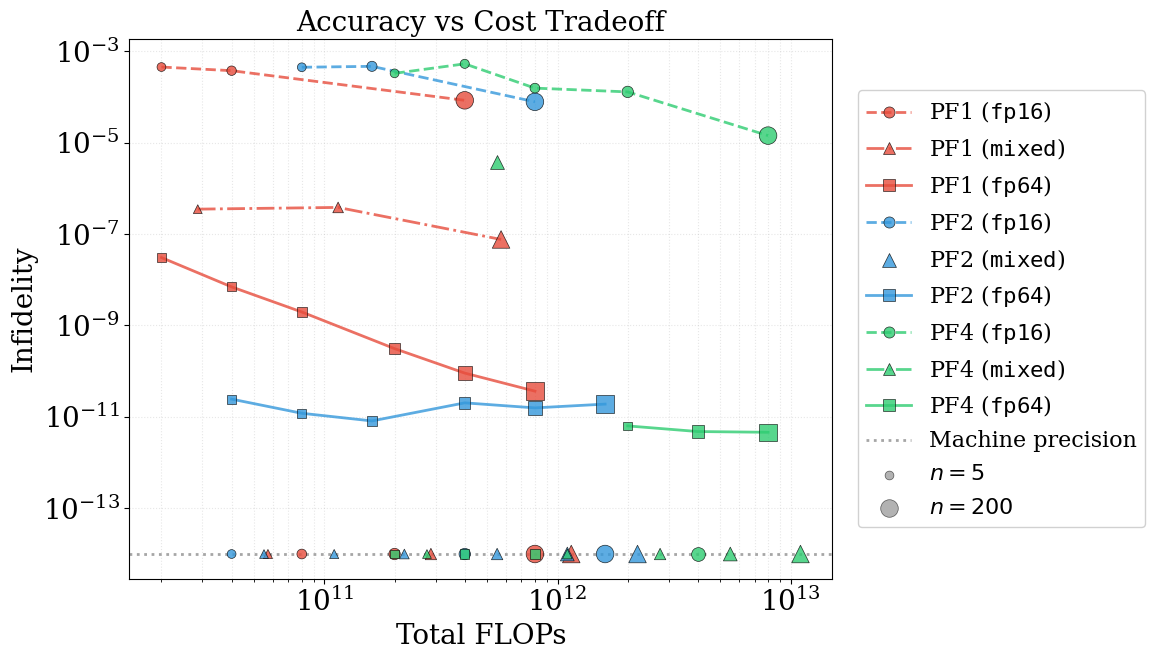

Plot saved to data/infidelity_vs_total_flops.pdf and data/infidelity_vs_total_flops.png
Using cost metric: total_flops, error metric: infidelity
Filtered out points with infidelity < 1e-14


In [55]:
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURATION: Change these to plot different metrics
# ============================================================
# Cost metric options: 'total_depth', 'total_flops'
# COST_METRIC = 'total_depth'
COST_METRIC = 'total_flops'  # Uncomment to use FLOPs instead

# Error metric options: 'infidelity', 'trace_distance' (if available)
ERROR_METRIC = 'infidelity'
# For accessing results with statistics
ERROR_METRIC_MEAN = ERROR_METRIC + '_mean'
ERROR_METRIC_STD = ERROR_METRIC + '_std'

# Minimum error threshold to avoid log scale issues
MIN_ERROR = 1e-14

# Metric display names
METRIC_LABELS = {
    'total_depth': 'Total Depth',
    'total_flops': 'Total FLOPs',
    'infidelity': 'Infidelity',
    'trace_distance': 'Trace Distance',
}
# ============================================================

# Set plot style
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 20
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['legend.fontsize'] = 16

# Load results
with open('data/tradeoff_results.pkl', 'rb') as f:
    all_results = pickle.load(f)

# Create plot
fig, ax = plt.subplots(1, 1, figsize=(12, 7))

# Define colors and markers for each configuration
# Colors = formula order, Markers = precision
formula_colors = {'First Order': '#E74C3C', 'Second Order': '#3498DB', 'Fourth Order': '#2ECC71'}
formula_labels = {'First Order': 'PF1', 'Second Order': 'PF2', 'Fourth Order': 'PF4'}
precision_markers = {'FP16': 'o', 'FP64': 's', 'Mixed': '^'}
precision_linestyles = {'FP16': '--', 'FP64': '-', 'Mixed': '-.'}
precision_labels = {'FP16': 'fp16', 'FP64': 'fp64', 'Mixed': 'mixed'}

# Group results by formula and precision
for formula_name in ['First Order', 'Second Order', 'Fourth Order']:
    for prec_name in ['FP16', 'Mixed', 'FP64']:
        # Filter results for this configuration
        config_results = [r for r in all_results 
                         if r['formula'] == formula_name and r['precision'] == prec_name]
        
        if not config_results:
            continue
        
        # Sort by cost metric
        config_results = sorted(config_results, key=lambda x: x[COST_METRIC])
        
        # Extract data and separate near-zero errors
        costs = []
        errors = []
        error_stds = []
        costs_zero = []  # For machine precision points
        for r in config_results:
            if r[ERROR_METRIC_MEAN] > MIN_ERROR:
                costs.append(r[COST_METRIC])
                errors.append(r[ERROR_METRIC_MEAN])
                error_stds.append(r[ERROR_METRIC_STD])
            else:
                # Store points that achieved machine precision
                costs_zero.append(r[COST_METRIC])
        
        if len(costs) == 0 and len(costs_zero) == 0:
            continue
        
        # Create label with short formula name and monospace precision
        label = f"{formula_labels[formula_name]} ($\\mathtt{{{precision_labels[prec_name]}}}$)"
        
        # Plot regular points with both lines and markers
        if len(costs) > 0:
            costs = np.array(costs)
            errors = np.array(errors)
            error_stds = np.array(error_stds)
            
            # Get n_steps for sizing markers
            n_steps_vals = np.array([r['n_steps'] for r in config_results 
                                     if r[ERROR_METRIC_MEAN] > MIN_ERROR])
            # Normalize marker sizes: scale n_steps to range (40-160)
            if len(n_steps_vals) > 1:
                marker_sizes = 40 + (n_steps_vals - n_steps_vals.min()) / (n_steps_vals.max() - n_steps_vals.min()) * 120
            else:
                marker_sizes = [100]  # Single point gets medium size
            
            # Plot line first (no label, no marker)
            ax.plot(costs, errors, 
                   color=formula_colors[formula_name],
                   linestyle=precision_linestyles[prec_name],
                   linewidth=2,
                   alpha=0.8)
            
            # Add error bars (std dev across trials)
            ax.errorbar(costs, errors, yerr=error_stds,
                       fmt='none',  # No line/marker, just error bars
                       ecolor=formula_colors[formula_name],
                       elinewidth=1,
                       capsize=3,
                       alpha=0.5,
                       zorder=4)
            
            # Add markers with variable size (no label)
            ax.scatter(costs, errors,
                      marker=precision_markers[prec_name],
                      s=marker_sizes,
                      color=formula_colors[formula_name],
                      edgecolors='black',
                      linewidths=0.5,
                      alpha=0.8,
                      zorder=5)
            
            # Add dummy plot for legend (line + marker)
            ax.plot([], [], 
                   marker=precision_markers[prec_name],
                   color=formula_colors[formula_name],
                   linestyle=precision_linestyles[prec_name],
                   linewidth=2,
                   markersize=8,
                   label=label,
                   markeredgecolor='black',
                   markeredgewidth=0.5,
                   alpha=0.8)
        
        # Plot machine precision points at the bottom (no label, same style)
        if len(costs_zero) > 0:
            costs_zero = np.array(costs_zero)
            # Plot at MIN_ERROR to show they achieved machine precision
            errors_zero = np.full_like(costs_zero, MIN_ERROR, dtype=float)
            
            # Get n_steps for these points
            n_steps_zero = np.array([r['n_steps'] for r in config_results 
                                    if r[ERROR_METRIC_MEAN] <= MIN_ERROR])
            if len(n_steps_zero) > 0:
                marker_sizes_zero = 40 + (n_steps_zero - step_counts[0]) / (step_counts[-1] - step_counts[0]) * 120
            else:
                marker_sizes_zero = [100]
            
            ax.scatter(costs_zero, errors_zero, 
                      marker=precision_markers[prec_name],
                      color=formula_colors[formula_name],  # Same filled markers
                      s=marker_sizes_zero,
                      edgecolors='black',
                      linewidths=0.5,
                      label=label if len(costs) == 0 else None,  # Only label if no regular points
                      alpha=0.8,
                      zorder=10)  # Plot on top

# Set log scale
ax.set_xscale('log')
ax.set_yscale('log')

# Add horizontal line at machine precision
ax.axhline(y=MIN_ERROR, color='gray', linestyle=':', linewidth=2, alpha=0.7, 
           label='Machine precision', zorder=1)



# Formatting with dynamic labels
ax.set_xlabel(METRIC_LABELS[COST_METRIC])
ax.set_ylabel(METRIC_LABELS[ERROR_METRIC])
ax.grid(True, which='both', alpha=0.3, linestyle=':')
ax.set_title('Accuracy vs Cost Tradeoff')

# Add size reference markers to legend
for n_step_ref in [step_counts[0], step_counts[-1]]:
    size_ref = 40 + (n_step_ref - step_counts[0]) / (step_counts[-1] - step_counts[0]) * 120
    ax.scatter([], [], s=size_ref, color='gray', edgecolors='black', linewidths=0.5,
              label=f'$n={n_step_ref}$', alpha=0.6)

# Place legend outside the plot area (to the right)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.9, ncol=1)

plt.tight_layout()

# Save with metric-specific filename
output_base = f'data/{ERROR_METRIC}_vs_{COST_METRIC}'
plt.savefig(f'{output_base}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{output_base}.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Plot saved to {output_base}.pdf and {output_base}.png")
print(f"Using cost metric: {COST_METRIC}, error metric: {ERROR_METRIC}")
print(f"Filtered out points with {ERROR_METRIC} < {MIN_ERROR}")

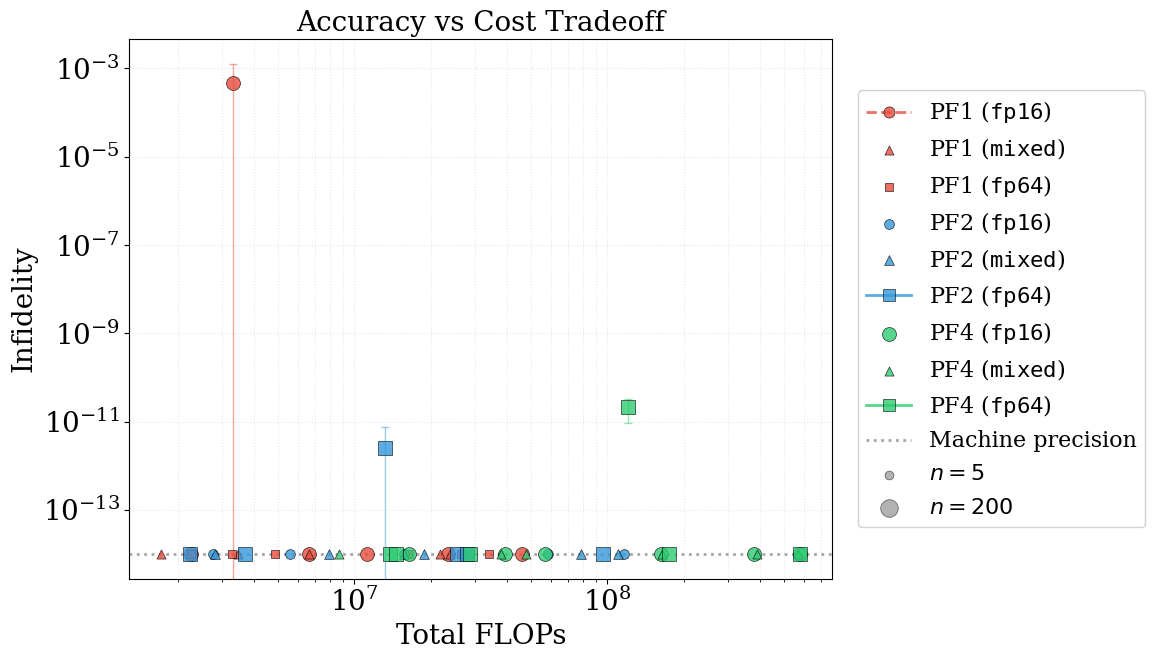

Plot saved to data/infidelity_vs_total_flops.pdf and data/infidelity_vs_total_flops.png
Using cost metric: total_flops, error metric: infidelity
Filtered out points with infidelity < 1e-14


In [ ]:
# ============================================================
# 4. Compare CostProfiles side-by-side
# ============================================================
print(f"\n{'Method':<12} {'Peak Mem (MB)':>14} {'FLOPs':>14} {'Depth':>10} {'Space×Time':>16} {'Error':>12}")
print("-" * 82)
for name, r in results.items():
    print(
        f"{name:<12}"
        f" {r.get('peak_memory_bytes', 0) / 1024**2:>13.2f}"
        f" {r.get('total_flops', 0):>14.2e}"
        f" {r.get('total_depth', 0):>10d}"
        f" {r.get('space_time_product', 0):>16.2e}"
        f" {r.get('error', 0):>12.2e}"
    )